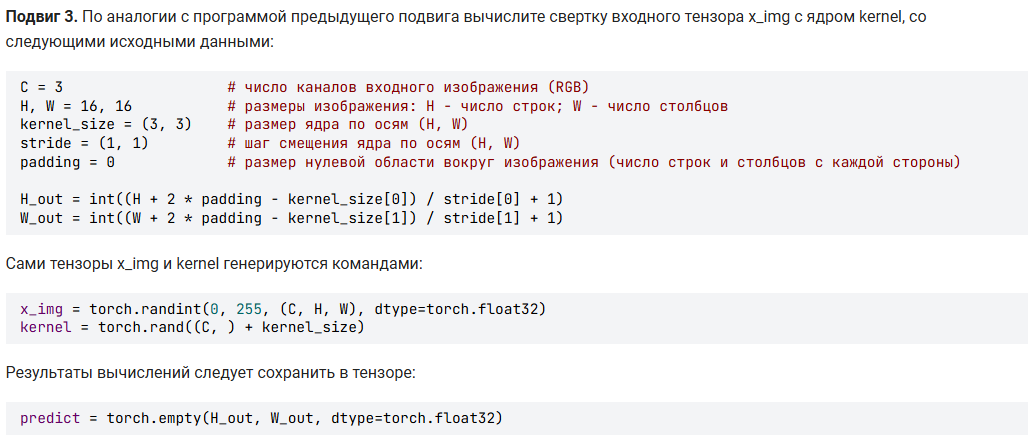

In [5]:
import torch

C = 3                   # число каналов
H, W = 16, 16           # размеры изображения: H - число строк; W - число столбцов
kernel_size = (3, 3)    # размер ядра по осям (H, W)
stride = (1, 1)         # шаг смещения ядра по осям (H, W)
padding = 0             # размер нулевой области вокруг изображения (число строк и столбцов с каждой стороны)

H_out = int((H + 2 * padding - kernel_size[0]) / stride[0] + 1)
W_out = int((W + 2 * padding - kernel_size[1]) / stride[1] + 1)

x_img = torch.randint(0, 255, (C, H, W), dtype=torch.float32) # тензоры x_img и kernel
kernel = torch.rand((C, ) + kernel_size) # в программе не менять

predict = torch.empty(H_out, W_out, dtype=torch.float32)

for i in range(0, H_out):
    for j in range(0, W_out):
        predict[i, j] = torch.sum(x_img[:, 
                                        i*stride[0]:kernel_size[0]+i*stride[0],
                                        j*stride[1]:kernel_size[1]+j*stride[1]] * kernel)



# здесь продолжайте программу

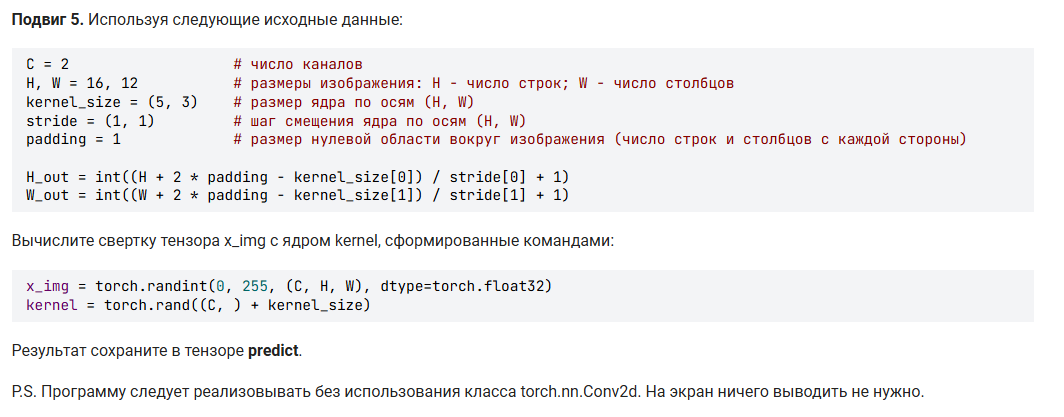

In [76]:
import torch

C = 2                   # число каналов
H, W = 16, 12           # размеры изображения: H - число строк; W - число столбцов
kernel_size = (5, 3)    # размер ядра по осям (H, W)
stride = (1, 1)         # шаг смещения ядра по осям (H, W)
padding = 1             # размер нулевой области вокруг изображения (число строк и столбцов с каждой стороны)

H_out = int((H + 2 * padding - kernel_size[0]) / stride[0] + 1)
W_out = int((W + 2 * padding - kernel_size[1]) / stride[1] + 1)

x_img = torch.randint(0, 255, (C, H, W), dtype=torch.float32) # тензоры x_img и kernel
x_img_padded = torch.nn.functional.pad(x_img, (padding, padding, padding, padding))
kernel = torch.rand((C, ) + kernel_size) # в программе не менять

predict = torch.empty(H_out, W_out, dtype=torch.float32)

# здесь продолжайте программу
for i in range(0, H_out):
    for j in range(0, W_out):
        predict[i, j] = torch.sum(x_img_padded[:, 
                                        i*stride[0]:kernel_size[0]+i*stride[0],
                                        j*stride[1]:kernel_size[1]+j*stride[1]] * kernel)


In [77]:
x_img_padded.shape

torch.Size([2, 18, 14])

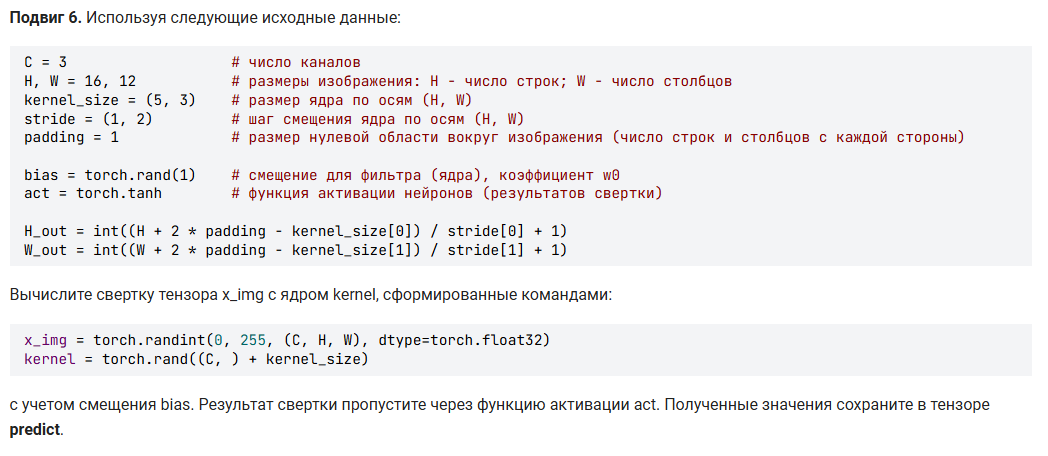

In [79]:
import torch

C = 3                   # число каналов
H, W = 16, 12           # размеры изображения: H - число строк; W - число столбцов
kernel_size = (5, 3)    # размер ядра по осям (H, W)
stride = (1, 2)         # шаг смещения ядра по осям (H, W)
padding = 1             # размер нулевой области вокруг изображения (число строк и столбцов с каждой стороны)

bias = torch.rand(1)    # смещение для фильтра (ядра), коэффициент w0
act = torch.tanh        # функция активации нейронов (результатов свертки)

H_out = int((H + 2 * padding - kernel_size[0]) / stride[0] + 1)
W_out = int((W + 2 * padding - kernel_size[1]) / stride[1] + 1)

x_img = torch.randint(0, 255, (C, H, W), dtype=torch.float32) # тензоры x_img и kernel
x_img_padded = torch.nn.functional.pad(x_img, (padding, padding, padding, padding))
kernel = torch.rand((C, ) + kernel_size) # в программе не менять

# здесь продолжайте программу
predict = torch.empty(H_out, W_out, dtype=torch.float32)

# здесь продолжайте программу
for i in range(0, H_out):
    for j in range(0, W_out):
        res = torch.sum(x_img_padded[:, 
                        i*stride[0]:kernel_size[0]+i*stride[0],
                        j*stride[1]:kernel_size[1]+j*stride[1]] * kernel)
        predict[i, j] = res
predict = act(predict+bias)

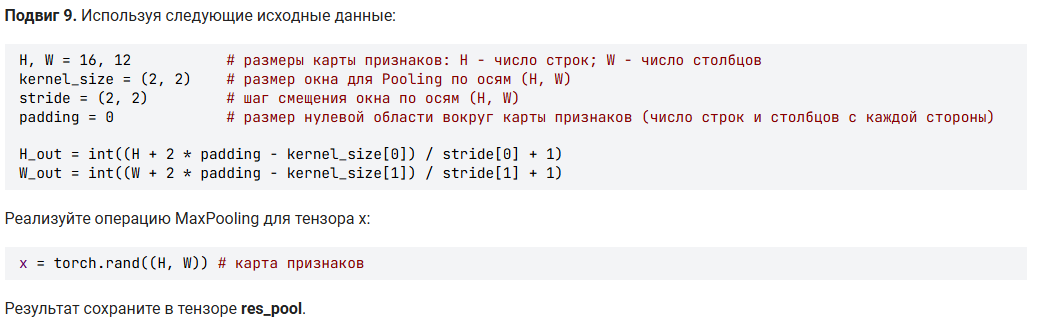

In [104]:
import torch

H, W = 16, 12           # размеры карты признаков: H - число строк; W - число столбцов
H, W = 12, 8   
kernel_size = (2, 2)    # размер окна для Pooling по осям (H, W)
stride = (2, 2)         # шаг смещения окна по осям (H, W)
padding = 0             # размер нулевой области вокруг карты признаков (число строк и столбцов с каждой стороны)

H_out = int((H + 2 * padding - kernel_size[0]) / stride[0] + 1)
W_out = int((W + 2 * padding - kernel_size[1]) / stride[1] + 1)

x = torch.rand((H, W)) # карта признаков (в программе не менять)

# здесь продолжайте программу

res_pool = torch.empty(H_out, W_out, dtype=torch.float32)

for i in range(0, H_out):
    for j in range(0, W_out):
        res_pool[i, j] = torch.max(x[i*stride[0]:kernel_size[0]+i*stride[0],
                                     j*stride[1]:kernel_size[1]+j*stride[1]])
res_pool

tensor([[0.5214, 0.9610, 0.6697, 0.8607],
        [0.7036, 0.7888, 0.7802, 0.6115],
        [0.5944, 0.8310, 0.7409, 0.9803],
        [0.9040, 0.6951, 0.9959, 0.6087],
        [0.6261, 0.9267, 0.8032, 0.9115],
        [0.5796, 0.9388, 0.8687, 0.9542]])

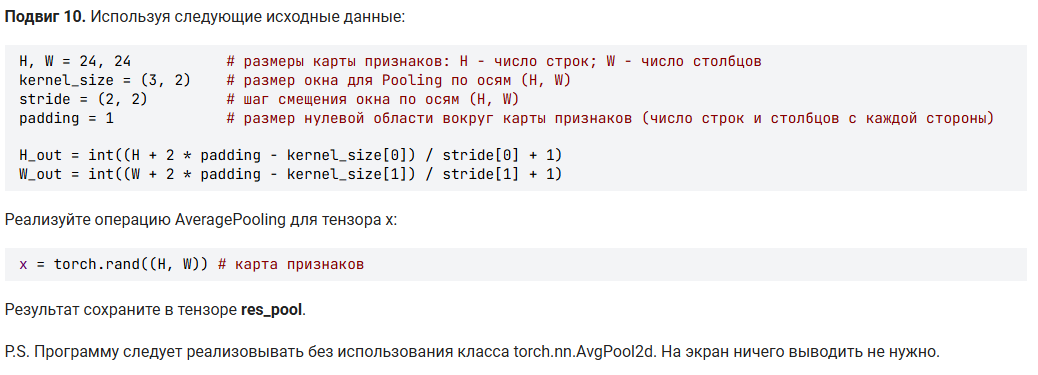

In [109]:
import torch

H, W = 24, 24           # размеры карты признаков: H - число строк; W - число столбцов
kernel_size = (3, 2)    # размер окна для Pooling по осям (H, W)
stride = (2, 2)         # шаг смещения окна по осям (H, W)
padding = 1             # размер нулевой области вокруг карты признаков (число строк и столбцов с каждой стороны)

H_out = int((H + 2 * padding - kernel_size[0]) / stride[0] + 1)
W_out = int((W + 2 * padding - kernel_size[1]) / stride[1] + 1)

x = torch.rand((H, W)) # карта признаков (в программе не менять)
x_padded = torch.nn.functional.pad(x, (padding, padding, padding, padding))

# здесь продолжайте программу
res_pool = torch.empty(H_out, W_out, dtype=torch.float32)

for i in range(0, H_out):
    for j in range(0, W_out):
        res_pool[i, j] = torch.mean(x_padded[i*stride[0]:kernel_size[0]+i*stride[0],
                                     j*stride[1]:kernel_size[1]+j*stride[1]])
res_pool

tensor([[0.1039, 0.2068, 0.4765, 0.4330, 0.3641, 0.4397, 0.3173, 0.3035, 0.3930,
         0.2235, 0.3436, 0.5425, 0.1095],
        [0.3452, 0.4021, 0.5897, 0.4839, 0.6160, 0.5612, 0.3548, 0.5457, 0.5808,
         0.5370, 0.5460, 0.5724, 0.1297],
        [0.4184, 0.6444, 0.4543, 0.5162, 0.5438, 0.6277, 0.5451, 0.6333, 0.4338,
         0.4028, 0.6613, 0.4933, 0.2060],
        [0.2456, 0.6902, 0.5306, 0.5693, 0.6397, 0.4991, 0.5602, 0.5209, 0.3920,
         0.4675, 0.5280, 0.4154, 0.3252],
        [0.2439, 0.4116, 0.8241, 0.5851, 0.7178, 0.3626, 0.5174, 0.5323, 0.6678,
         0.3514, 0.5187, 0.4474, 0.3151],
        [0.1349, 0.5022, 0.6271, 0.4165, 0.5239, 0.4543, 0.4708, 0.4849, 0.5348,
         0.6216, 0.4173, 0.3758, 0.1558],
        [0.1681, 0.6112, 0.4878, 0.5433, 0.4418, 0.5243, 0.5720, 0.3857, 0.4218,
         0.5810, 0.4837, 0.1735, 0.1045],
        [0.3586, 0.5708, 0.5080, 0.5269, 0.5270, 0.5315, 0.3102, 0.4598, 0.3786,
         0.4625, 0.3663, 0.5821, 0.2710],
        [0.2951,

In [107]:
[1]*4

[1, 1, 1, 1]